# ผลการทดลอง: เทียบโมเดล และผลของ PCA

ทุกตัวเลขในสมุดนี้อ่านมาจาก `results/metrics.csv` ที่ `python -m src.train` เขียนไว้
ไม่มีการเทรนซ้ำและไม่มีตัวเลขที่พิมพ์เอง

| | เนื้อหา |
|---|---|
| F1 | ตารางเทียบโมเดลที่มิติเต็ม + baseline TF-IDF |
| F2 | macro-F1 เทียบกับจำนวนมิติ |
| F3 | cumulative explained variance ของ PCA |
| F4 | เวลา predict และขนาด vector เทียบกับจำนวนมิติ |
| F5 | scatter PC1 vs PC2 แยกสีตามคลาส |
| F6 | confusion matrix ของ config ที่ดีที่สุด |
| F7 | ตารางก่อน/หลัง PCA ที่มิติคุ้มที่สุด |

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config, data, evaluate, features, plotting

plotting.setup()

metrics = pd.read_csv(config.METRICS_FILE)
print(f"{len(metrics)} rows in metrics.csv")
metrics.head()

30 rows in metrics.csv


,feature,dims,model,best_params,macro_f1,accuracy,f1_neg,f1_neu,f1_pos,train_sec,predict_sec,vector_mb,explained_var
0,tfidf,50000,logreg,"{""C"": 1}",0.631451,0.707951,0.527363,0.565741,0.801247,4.557699,0.004888,1199.800000,NaN
1,tfidf,50000,linear_svm,"{""C"": 0.1}",0.640601,0.733122,0.552023,0.540915,0.828865,0.893152,0.005144,1199.800000,NaN
2,bge-m3,1024,logreg,"{""C"": 1}",0.603208,0.677780,0.503171,0.524830,0.781622,6.696377,0.005952,24.571904,1.0
3,bge-m3,1024,linear_svm,"{""C"": 1}",0.619044,0.710285,0.533844,0.508595,0.814692,18.382288,0.018322,24.571904,1.0
4,bge-m3,1024,knn,"{""n_neighbors"": 15}",0.487958,0.670445,0.359202,0.309764,0.794906,0.053144,2.835812,24.571904,1.0


In [2]:
# Thai labels for the figures, so the report does not mix languages
MODEL_NAMES = {
    "logreg": "Logistic Regression",
    "linear_svm": "Linear SVM",
    "knn": "kNN (cosine)",
    "lightgbm": "LightGBM",
}
LABEL_NAMES = {"negative": "เชิงลบ", "neutral": "กลางๆ", "positive": "เชิงบวก"}

embed = metrics[metrics["feature"] == config.EMBEDDING_NAME].copy()
tfidf = metrics[metrics["feature"] == "tfidf"].copy()
full = embed[embed["dims"] == config.EMBEDDING_DIMS]

print(f"embedding runs: {len(embed)}   tfidf runs: {len(tfidf)}")

embedding runs: 28   tfidf runs: 2


## F1 เทียบโมเดลที่มิติเต็ม (bge-m3 1024 มิติ) กับ baseline TF-IDF

In [3]:
columns = ["feature", "dims", "model", "best_params", "macro_f1", "accuracy",
           "f1_neg", "f1_neu", "f1_pos", "train_sec", "predict_sec"]
f1_table = pd.concat([tfidf, full])[columns].sort_values("macro_f1", ascending=False)
f1_table = f1_table.reset_index(drop=True)
f1_table.round(4)

,feature,dims,model,best_params,macro_f1,accuracy,f1_neg,f1_neu,f1_pos,train_sec,predict_sec
0,tfidf,50000,linear_svm,"{""C"": 0.1}",0.6406,0.7331,0.5520,0.5409,0.8289,0.8932,0.0051
1,tfidf,50000,logreg,"{""C"": 1}",0.6315,0.7080,0.5274,0.5657,0.8012,4.5577,0.0049
2,bge-m3,1024,lightgbm,"{""num_leaves"": 31}",0.6238,0.6968,0.5665,0.5103,0.7947,73.7118,0.0887
3,bge-m3,1024,linear_svm,"{""C"": 1}",0.6190,0.7103,0.5338,0.5086,0.8147,18.3823,0.0183
4,bge-m3,1024,logreg,"{""C"": 1}",0.6032,0.6778,0.5032,0.5248,0.7816,6.6964,0.0060
5,bge-m3,1024,knn,"{""n_neighbors"": 15}",0.4880,0.6704,0.3592,0.3098,0.7949,0.0531,2.8358


In [4]:
best_tfidf = tfidf.loc[tfidf["macro_f1"].idxmax()]
best_overall = metrics.loc[metrics["macro_f1"].idxmax()]
gain = best_overall["macro_f1"] - best_tfidf["macro_f1"]

print(f"baseline ดีสุด : {best_tfidf['model']} (TF-IDF) macro-F1 {best_tfidf['macro_f1']:.4f}")
print(f"ดีที่สุดรวม    : {best_overall['model']} @ {best_overall['dims']} มิติ "
      f"macro-F1 {best_overall['macro_f1']:.4f}")
print(f"ต่างกัน        : {gain:+.4f} ({gain * 100:+.1f} จุด)")

baseline ดีสุด : linear_svm (TF-IDF) macro-F1 0.6406
ดีที่สุดรวม    : linear_svm @ 50000 มิติ macro-F1 0.6406
ต่างกัน        : +0.0000 (+0.0 จุด)


## F2 macro-F1 เทียบกับจำนวนมิติ

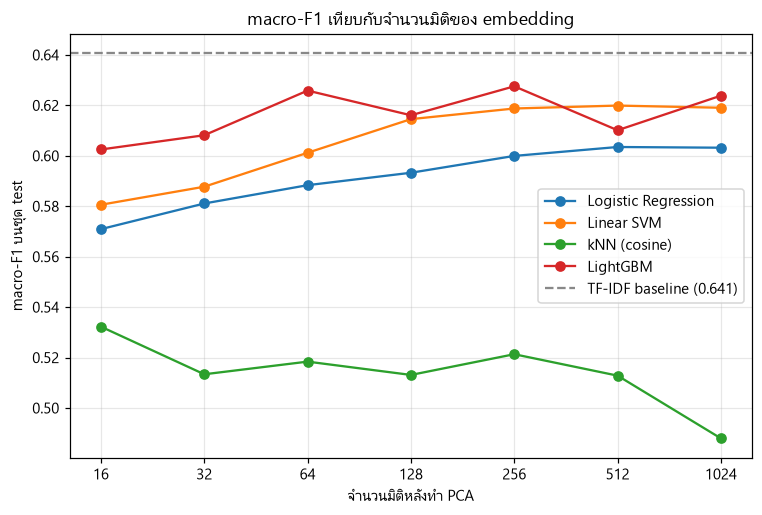

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))

for model_name in config.MODELS:
    part = embed[embed["model"] == model_name].sort_values("dims")
    if part.empty:
        continue
    ax.plot(part["dims"], part["macro_f1"], marker="o", label=MODEL_NAMES[model_name])

ax.axhline(best_tfidf["macro_f1"], color="#888888", linestyle="--", linewidth=1.5,
           label=f"TF-IDF baseline ({best_tfidf['macro_f1']:.3f})")

ax.set_xscale("log", base=2)
ax.set_xticks(config.PCA_DIMS)
ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
ax.set_xlabel("จำนวนมิติหลังทำ PCA")
ax.set_ylabel("macro-F1 บนชุด test")
ax.set_title("macro-F1 เทียบกับจำนวนมิติของ embedding")
ax.legend()

plotting.save(fig, "res_f1_vs_dims")

## F3 cumulative explained variance

90% ของความแปรปรวน ใช้ 281 มิติ
95% ของความแปรปรวน ใช้ 374 มิติ


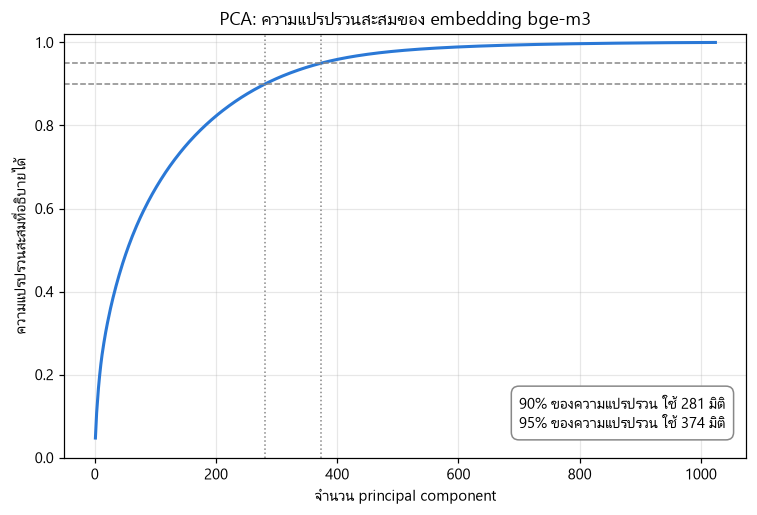

In [6]:
ratio = np.load(config.EXPLAINED_VARIANCE_FILE)
cumulative = np.cumsum(ratio)
components = np.arange(1, len(cumulative) + 1)

thresholds = {}
for threshold in (0.90, 0.95):
    thresholds[threshold] = int(np.searchsorted(cumulative, threshold) + 1)
    print(f"{threshold:.0%} ของความแปรปรวน ใช้ {thresholds[threshold]} มิติ")

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(components, cumulative, color=config.BAR_COLOR, linewidth=2)

for threshold, needed in thresholds.items():
    ax.axhline(threshold, color="#888888", linestyle="--", linewidth=1)
    ax.axvline(needed, color="#888888", linestyle=":", linewidth=1)

# Both labels go in the empty lower right, so they never cross the guide lines
lines = [f"{threshold:.0%} ของความแปรปรวน ใช้ {needed} มิติ"
         for threshold, needed in thresholds.items()]
ax.text(0.97, 0.06, "\n".join(lines), transform=ax.transAxes,
        ha="right", va="bottom",
        bbox={"facecolor": "white", "edgecolor": "#888888", "boxstyle": "round,pad=0.5"})

ax.set_xlabel("จำนวน principal component")
ax.set_ylabel("ความแปรปรวนสะสมที่อธิบายได้")
ax.set_title("PCA: ความแปรปรวนสะสมของ embedding bge-m3")
ax.set_ylim(0, 1.02)

plotting.save(fig, "pca_explained_variance")

## F4 ต้นทุน: เวลา predict และขนาด vector

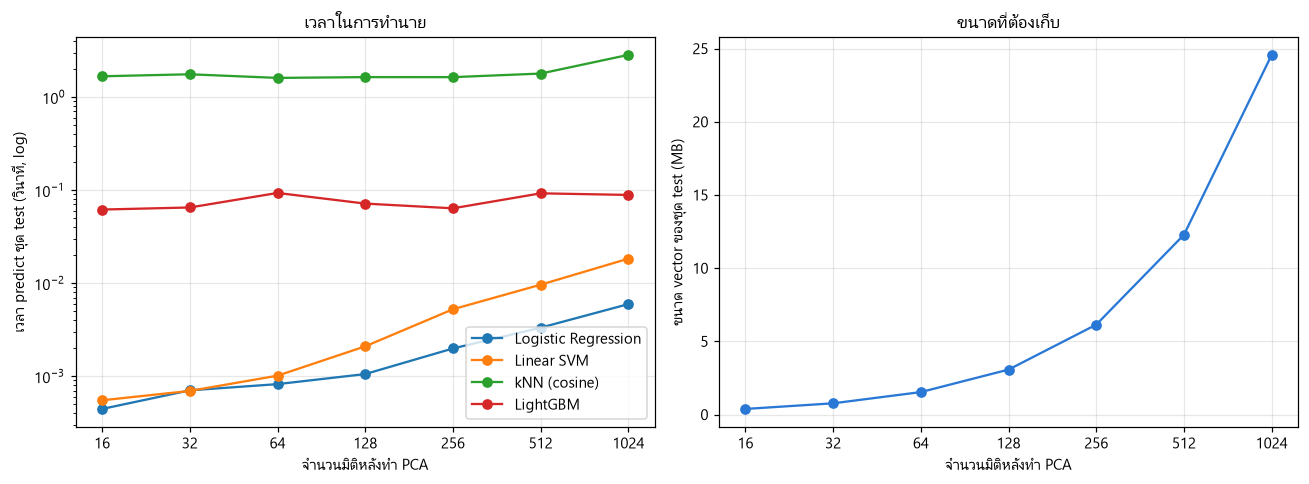

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for model_name in config.MODELS:
    part = embed[embed["model"] == model_name].sort_values("dims")
    if part.empty:
        continue
    axes[0].plot(part["dims"], part["predict_sec"], marker="o", label=MODEL_NAMES[model_name])

axes[0].set_yscale("log")
axes[0].set_ylabel("เวลา predict ชุด test (วินาที, log)")
axes[0].set_title("เวลาในการทำนาย")
axes[0].legend()

size = embed.drop_duplicates("dims").sort_values("dims")
axes[1].plot(size["dims"], size["vector_mb"], marker="o", color=config.BAR_COLOR)
axes[1].set_ylabel("ขนาด vector ของชุด test (MB)")
axes[1].set_title("ขนาดที่ต้องเก็บ")

for ax in axes:
    ax.set_xscale("log", base=2)
    ax.set_xticks(config.PCA_DIMS)
    ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
    ax.set_xlabel("จำนวนมิติหลังทำ PCA")

fig.tight_layout()
plotting.save(fig, "pca_cost_vs_dims")

## F5 scatter PC1 vs PC2

สองมิติแรกอธิบายความแปรปรวนรวม 7.8%


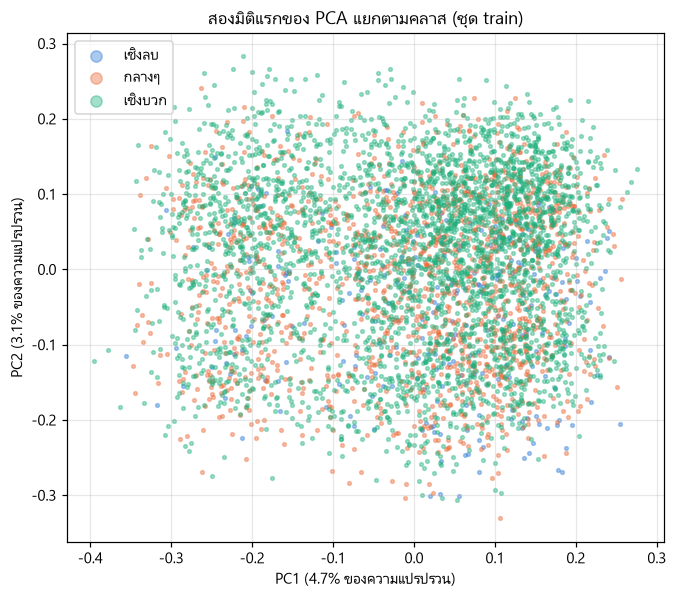

In [8]:
from sklearn.decomposition import PCA

train_vectors = features.load_embeddings("train")
train_labels = data.load_split("train")["label"].to_numpy()

pca_2d = PCA(n_components=2, random_state=config.SEED).fit(train_vectors)
points = pca_2d.transform(train_vectors)

# Thin out the cloud so the classes stay visible on top of each other
rng = np.random.default_rng(config.SEED)
sample = rng.choice(len(points), size=min(5000, len(points)), replace=False)

fig, ax = plt.subplots(figsize=(7, 6))
for label in config.LABELS:
    mask = train_labels[sample] == label
    ax.scatter(points[sample][mask, 0], points[sample][mask, 1],
               s=6, alpha=0.4, color=config.LABEL_COLORS[label], label=LABEL_NAMES[label])

variance = pca_2d.explained_variance_ratio_
ax.set_xlabel(f"PC1 ({variance[0]:.1%} ของความแปรปรวน)")
ax.set_ylabel(f"PC2 ({variance[1]:.1%} ของความแปรปรวน)")
ax.set_title("สองมิติแรกของ PCA แยกตามคลาส (ชุด train)")
ax.legend(markerscale=3)

plotting.save(fig, "pca_scatter_2d")
print(f"สองมิติแรกอธิบายความแปรปรวนรวม {variance.sum():.1%}")

## F6 confusion matrix ของ config ที่ดีที่สุด

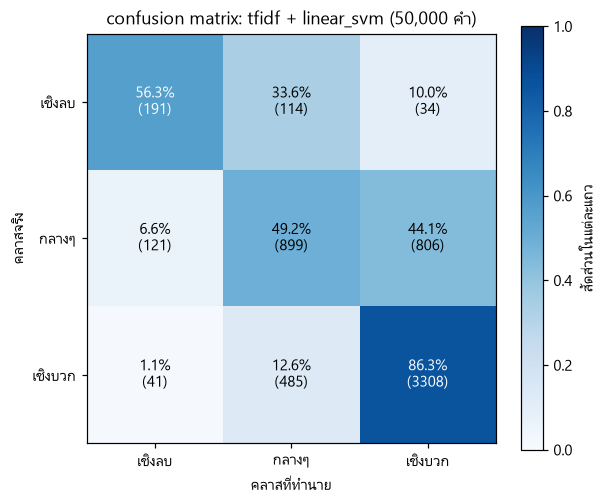

In [9]:
predictions = pd.read_parquet(config.PREDICTIONS_FILE)
matrix = evaluate.confusion(predictions["y_true"], predictions["y_pred"])
normalized = matrix / matrix.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(6, 5))
image = ax.imshow(normalized, cmap="Blues", vmin=0, vmax=1)

names = [LABEL_NAMES[label] for label in config.LABELS]
ax.set_xticks(range(len(names)), names)
ax.set_yticks(range(len(names)), names)
ax.set_xlabel("คลาสที่ทำนาย")
ax.set_ylabel("คลาสจริง")
# TF-IDF reports a vocabulary size, not a PCA dimension, so word the two cases apart
if best_overall["feature"] == config.EMBEDDING_NAME:
    size = f"{best_overall['dims']} มิติ"
else:
    size = f"{best_overall['dims']:,} คำ"
ax.set_title(f"confusion matrix: {best_overall['feature']} + {best_overall['model']} ({size})")
ax.grid(False)

for i in range(len(names)):
    for j in range(len(names)):
        color = "white" if normalized[i, j] > 0.5 else "black"
        ax.text(j, i, f"{normalized[i, j]:.1%}\n({matrix[i, j]})",
                ha="center", va="center", color=color)

fig.colorbar(image, ax=ax, label="สัดส่วนในแต่ละแถว")
plotting.save(fig, "res_confusion_best")

## F7 ก่อน vs หลัง PCA ที่มิติคุ้มที่สุด

"คุ้มที่สุด" = มิติต่ำสุดที่ macro-F1 ยังลดลงจากมิติเต็มไม่ถึง 1 จุด

In [10]:
TOLERANCE = 0.01

rows = []
for model_name in config.MODELS:
    part = embed[embed["model"] == model_name].sort_values("dims")
    if part.empty:
        continue
    baseline = part[part["dims"] == config.EMBEDDING_DIMS].iloc[0]
    affordable = part[part["macro_f1"] >= baseline["macro_f1"] - TOLERANCE]
    chosen = affordable.loc[affordable["dims"].idxmin()]

    rows.append({
        "model": MODEL_NAMES[model_name],
        "macro_f1 @1024": baseline["macro_f1"],
        "มิติที่คุ้ม": int(chosen["dims"]),
        "macro_f1 หลัง PCA": chosen["macro_f1"],
        "ส่วนต่าง": chosen["macro_f1"] - baseline["macro_f1"],
        "explained_var": chosen["explained_var"],
        "predict เร็วขึ้น": baseline["predict_sec"] / chosen["predict_sec"],
        "ขนาดเหลือ": chosen["vector_mb"] / baseline["vector_mb"],
    })

f7_table = pd.DataFrame(rows)
f7_table.round(4)

,model,macro_f1 @1024,มิติที่คุ้ม,macro_f1 หลัง PCA,ส่วนต่าง,explained_var,predict เร็วขึ้น,ขนาดเหลือ
0,Logistic Regression,0.6032,128,0.5933,-0.0099,0.7105,5.6440,0.1250
1,Linear SVM,0.6190,128,0.6145,-0.0045,0.7105,8.7490,0.1250
2,kNN (cosine),0.4880,16,0.5323,0.0443,0.2856,1.6988,0.0156
3,LightGBM,0.6238,64,0.6259,0.0020,0.5410,0.9520,0.0625


## Error analysis

ดูว่า config ที่ดีที่สุดพลาดตรงไหน ใช้เขียนบทที่ 7

In [11]:
test = data.load_split("test")
errors = predictions.merge(test[["id", "text", "star"]], on="id")
errors = errors[errors["y_true"] != errors["y_pred"]]

print(f"ทายผิด {len(errors)} จาก {len(predictions)} ({len(errors) / len(predictions):.1%})")
print()
pair_counts = errors.groupby(["y_true", "y_pred"]).size().sort_values(ascending=False)
print(pair_counts.to_string())

ทายผิด 1601 จาก 5999 (26.7%)

y_true    y_pred  
neutral   positive    806
positive  neutral     485
neutral   negative    121
negative  neutral     114
positive  negative     41
negative  positive     34


In [12]:
# The neutral class has no vocabulary of its own (ดู EDA หัวข้อ 4) so most of the
# damage is expected to sit in the neutral rows
rng = np.random.default_rng(config.SEED)

for true_label, pred_label in pair_counts.index[:4]:
    group = errors[(errors["y_true"] == true_label) & (errors["y_pred"] == pred_label)]
    picked = group.iloc[rng.choice(len(group), size=min(3, len(group)), replace=False)]
    print(f"=== จริง {true_label} -> ทาย {pred_label}  ({len(group)} รีวิว) ===")
    for _, row in picked.iterrows():
        print(f"  [{row['star']} ดาว] {row['text'][:220]}")
    print()

=== จริง neutral -> ทาย positive  (806 รีวิว) ===
  [3 ดาว] แวะออกมาหาอะไรทาน วันนี้ (22/Dec) แปลกจังหลายๆ ร้านค้าปิด 1 วัน ขับมาเรื่อยๆ เส้นสันกำแพง ร้านนี้เปิดแวะเข้ามาลองหน่อย ตามเค้ามา ด้านในมีที่จอด แต่ถ้าเต็มก็ต้องไปจอดริมถนน ทางร้านบริการเมนูก๋วยเตี๋ยวเป็ด ข้าวหน้าเป็ด หมู
  [3 ดาว] ร้านอาหารนี้อยู่แถวอ่างศิลา ซึ่งบริเวณนี้จะมีร้านอาหารหลายร้านตั้งเรียงกันเลยทีเดียว บรรยากาศของร้านถือว่าดีเลยทีเดียว อยู่ติดทะเล ลมพัดมาเย็นสบาย :) เมนูที่ได้ลองทานวันนี้มีประมาณ6-7อย่าง เนื่องจากมากันหลายคนเลยไม่ได้ถ่
  [3 ดาว] Au Bon Pain ณ ชั้น1 Empire Tower อยู่โซนหน้าลิฟต์ขึ้นอาคารสำนักงานต่างๆ กะว่าจะแวะแต่รีบขึ้นไปลงทะเบียนสัมมนาก่อนซะหน่อย เหมือนใจหวัง เบรคจัดของโอปองแปงให้พร้อมพนักงานจากร้านมาดูแลผู้เข้าร่วมเลยค่ะ ???ชามะนาว เราว่าดีงาม

=== จริง positive -> ทาย neutral  (485 รีวิว) ===
  [4 ดาว] ไม่รู้จะเรียกว่าฟิวชั่นรึป่าว แต่ร้านนี้ขายอาหารญี่ปุ่นค่ะ แซมๆสปาเกตตี้มาหน่อยๆ 4-5 เมนู ยังลองไม่หมดนะ แต่เมนูที่ทานไปก็อร่อยดีค่ะ อุด้งน้ำซุปหอมดี ชอบอีกอย่างคือ ร้านนี้ตกแต่งสวยดีค่ะ บรรยากาศส

In [13]:
# Does length explain the errors? EDA said length is a weak signal, so this is a check
merged = predictions.merge(test[["id", "text"]], on="id")
merged["chars"] = merged["text"].str.len()
merged["correct"] = merged["y_true"] == merged["y_pred"]
merged.groupby("correct")["chars"].describe()[["count", "mean", "50%"]].round(1)

,count,mean,50%
correct,,,
False,1601.0,516.4,372.0
True,4398.0,548.1,372.0


### สรุปสำหรับบทที่ 7

_เติมหลังรันจริง: จัดกลุ่มข้อผิดพลาดจากตัวอย่างด้านบน เช่น 3 ดาวที่เนื้อหาเป็นคำชม,
ประชด, รีวิวยาวที่มีทั้งชมและติ, การปฏิเสธที่ TF-IDF จับไม่ได้_